In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow sürümü:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow sürümü: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)
print("İlk etiket:", y_train[0])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Eğitim verisi: (60000, 28, 28)
Test verisi: (10000, 28, 28)
İlk etiket: 5


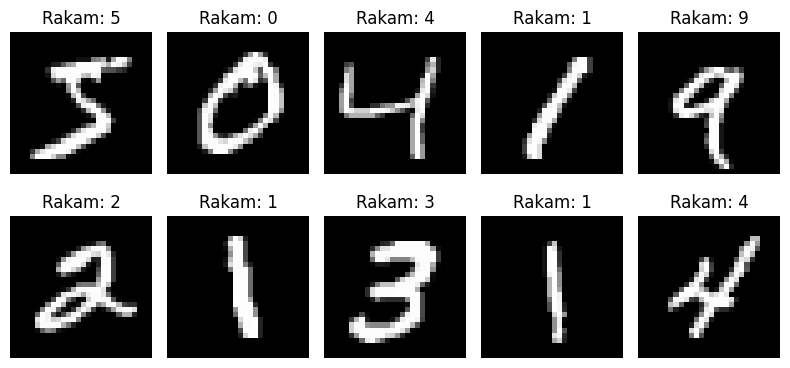

In [3]:
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Rakam: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
x_train = x_train.astype("float32")

x_train = x_train / 127.5 - 1.0

x_train = np.expand_dims(x_train, axis=-1)

print("Yeni şekil:", x_train.shape)
print("En küçük değer:", x_train.min())
print("En büyük değer:", x_train.max())


Yeni şekil: (60000, 28, 28, 1)
En küçük değer: -1.0
En büyük değer: 1.0


In [5]:
def build_generator():

    model = keras.Sequential(name="Generator")

    model.add(layers.Input(shape=(100,)))

    model.add(layers.Dense(256))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))

    model.add(layers.Dense(512))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))

    model.add(layers.Dense(1024))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))

    model.add(layers.Dense(784, activation="tanh"))

    model.add(layers.Reshape((28, 28, 1)))

    return model


generator = build_generator()

generator.summary()


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,493,520 (5.70 MB)

 Trainable params: 1,489,936 (5.68 MB)

 Non-trainable params: 3,584 (14.00 KB)

Noise shape: (1, 100)
Generated image shape: (1, 28, 28, 1)


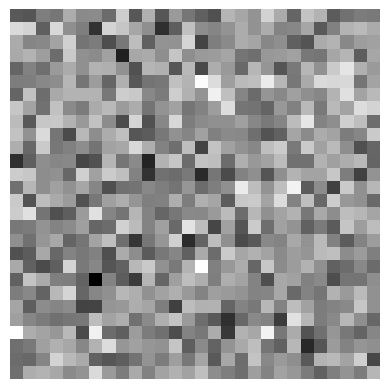

In [6]:
noise = np.random.normal(0, 1, (1, 100))

fake_image = generator(noise, training=False).numpy()

print("Noise shape:", noise.shape)
print("Generated image shape:", fake_image.shape)

plt.imshow(fake_image[0, :, :, 0], cmap="gray")
plt.axis("off")
plt.show()


In [7]:
def build_discriminator():

    model = keras.Sequential(name="Discriminator")

    model.add(layers.Input(shape=(28, 28, 1)))

    model.add(layers.Flatten())

    model.add(layers.Dense(512))
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Dense(256))
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Dense(1, activation="sigmoid"))

    return model


discriminator = build_discriminator()

discriminator.summary()


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
real_image = x_train[:1]

prediction = discriminator(real_image, training=False)

print("Tahmin:", prediction.numpy())


Tahmin: [[0.30351514]]


In [9]:
loss_fn = keras.losses.BinaryCrossentropy()

g_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

d_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

latent_dim = 100
batch_size = 64


In [10]:
@tf.function
def train_step(real_images):

    current_batch_size = tf.shape(real_images)[0]

    # 1. Discriminator eğitimi
    noise = tf.random.normal(
        (current_batch_size, latent_dim)
    )

    with tf.GradientTape() as d_tape:

        fake_images = generator(noise, training=False)

        real_predictions = discriminator(
            real_images, training=True
        )

        fake_predictions = discriminator(
            fake_images, training=True
        )

        real_loss = loss_fn(
            tf.ones_like(real_predictions),
            real_predictions
        )

        fake_loss = loss_fn(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        d_loss = (real_loss + fake_loss) / 2

    d_gradients = d_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(
            d_gradients,
            discriminator.trainable_variables
        )
    )

    # 2. Generator eğitimi
    noise = tf.random.normal(
        (current_batch_size, latent_dim)
    )

    with tf.GradientTape() as g_tape:

        fake_images = generator(noise, training=True)

        fake_predictions = discriminator(
            fake_images, training=False
        )

        g_loss = loss_fn(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

    g_gradients = g_tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(
            g_gradients,
            generator.trainable_variables
        )
    )

    return d_loss, g_loss


In [11]:
dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)


In [12]:
epochs = 5

d_losses = []
g_losses = []

for epoch in range(epochs):

    d_epoch = []
    g_epoch = []

    for real_batch in dataset:

        d_loss, g_loss = train_step(real_batch)

        d_epoch.append(float(d_loss))
        g_epoch.append(float(g_loss))

    d_mean = np.mean(d_epoch)
    g_mean = np.mean(g_epoch)

    d_losses.append(d_mean)
    g_losses.append(g_mean)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"D Loss: {d_mean:.4f} | "
        f"G Loss: {g_mean:.4f}"
    )


Epoch 1/5 | D Loss: 0.4469 | G Loss: 1.6444
Epoch 2/5 | D Loss: 0.5982 | G Loss: 0.9046
Epoch 3/5 | D Loss: 0.5945 | G Loss: 0.9272
Epoch 4/5 | D Loss: 0.6111 | G Loss: 0.9018
Epoch 5/5 | D Loss: 0.6189 | G Loss: 0.8925


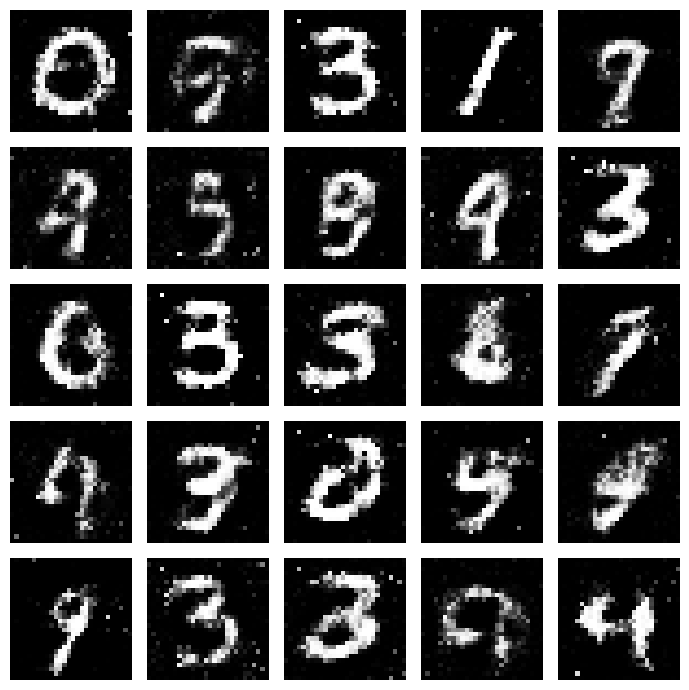

In [13]:
def show_generated_images(generator, num_images=25):

    noise = tf.random.normal((num_images, 100))

    images = generator(
        noise, training=False
    ).numpy()

    images = (images + 1) / 2

    fig, axes = plt.subplots(
        5, 5, figsize=(7, 7)
    )

    for i, ax in enumerate(axes.flat):
        ax.imshow(
            images[i, :, :, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_generated_images(generator)


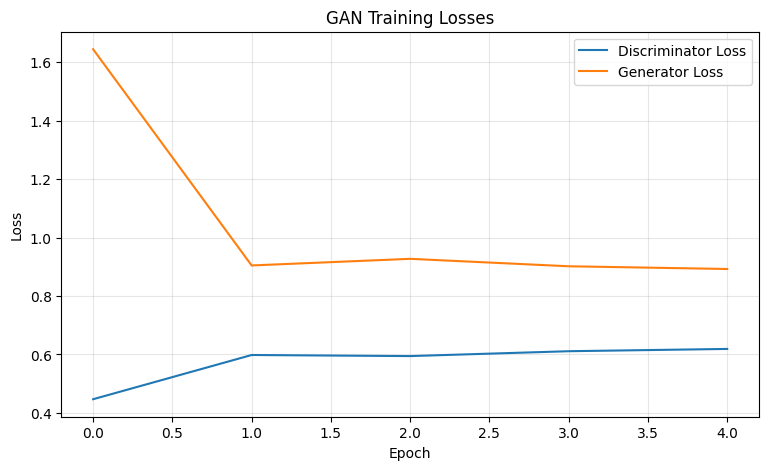

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(d_losses, label="Discriminator Loss")
plt.plot(g_losses, label="Generator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")

plt.legend()
plt.grid(alpha=0.3)

plt.show()
